# Proyek Analisis Data: E-Commerce Public Dataset

- **Nama:** Awalin Nisa'Ul Mufidah
- **Email:** DS466B6X0293@student.devacademy.id
- **ID Dicoding:** DS466B6X0293

## Menentukan Pertanyaan Bisnis

Dataset yang dipakai adalah E-Commerce Public Dataset, berisi transaksi sebuah marketplace di Brasil. Rentang order di data mentah adalah September 2016 sampai Oktober 2018, tetapi bulan yang datanya lengkap hanya **Januari 2017 sampai Agustus 2018**. Karena itu semua pertanyaan dibatasi pada rentang tersebut, dan perbandingan antartahun memakai periode yang sama (Januari sampai Agustus) supaya adil.

1. **Bagaimana perbandingan jumlah order dan total pendapatan per bulan antara periode Januari-Agustus 2017 dan Januari-Agustus 2018, dan kategori produk apa saja yang menyumbang pendapatan terbesar pada Januari-Agustus 2018?**
   - *Specific*: fokus pada order, pendapatan, dan kategori produk.
   - *Measurable*: jumlah order (order unik) dan pendapatan (jumlah harga barang, dalam BRL).
   - *Action-oriented*: hasilnya menentukan kategori mana yang diprioritaskan untuk stok dan promosi.
   - *Relevant*: pertumbuhan penjualan adalah indikator utama kesehatan bisnis marketplace.
   - *Time-bound*: Januari-Agustus 2017 dibanding Januari-Agustus 2018.

2. **Di state mana rata-rata review score pelanggan paling rendah pada Januari-Agustus 2018, dan seberapa besar perbedaan review score antara order yang terlambat dan yang tepat waktu (tanggal sampai dibanding tanggal estimasi)?**
   - *Specific*: review score per state dan hubungannya dengan keterlambatan pengiriman.
   - *Measurable*: rata-rata review score (skala 1-5) dan selisih rata-rata antara order terlambat dan tepat waktu.
   - *Action-oriented*: menunjukkan wilayah yang perlu perbaikan logistik lebih dulu.
   - *Relevant*: kepuasan pelanggan memengaruhi pembelian ulang.
   - *Time-bound*: order yang dibeli Januari-Agustus 2018.

3. **Segmen pelanggan mana (berdasarkan analisis RFM) yang memberi kontribusi pendapatan terbesar sepanjang seluruh order terkirim yang tercatat (September 2016-Agustus 2018), dan di wilayah mana pelanggan bernilai tinggi tersebut paling banyak terkonsentrasi?**
   - *Specific*: segmentasi pelanggan unik dan sebaran wilayahnya.
   - *Measurable*: skor Recency, Frequency, Monetary dan persentase kontribusi pendapatan tiap segmen.
   - *Action-oriented*: menentukan segmen yang perlu dipertahankan dan wilayah target kampanye.
   - *Relevant*: sebagian besar pendapatan biasanya datang dari pelanggan bernilai tinggi.
   - *Time-bound*: seluruh order terkirim, September 2016-Agustus 2018 (hampir seluruhnya Januari 2017 ke atas, karena 2016 hanya 267 order terkirim).

## Menyiapkan semua library yang dibutuhkan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

Dataset terdiri dari sembilan tabel. Tabel geolocation versi asli berukuran sekitar 59 MB karena satu kode pos punya banyak titik koordinat. Tabel tersebut diringkas lebih dulu menjadi satu titik rata-rata per kode pos (`geolocation_ringkas.csv`) agar ringan dipakai di notebook maupun dashboard. Tabel asli tidak diubah isinya, hanya dikelompokkan per kode pos.

In [2]:
path = "data/"

customers_df = pd.read_csv(path + "customers_dataset.csv")
geolocation_df = pd.read_csv(path + "geolocation_ringkas.csv")
order_items_df = pd.read_csv(path + "order_items_dataset.csv")
order_payments_df = pd.read_csv(path + "order_payments_dataset.csv")
order_reviews_df = pd.read_csv(path + "order_reviews_dataset.csv")
orders_df = pd.read_csv(path + "orders_dataset.csv")
products_df = pd.read_csv(path + "products_dataset.csv")
sellers_df = pd.read_csv(path + "sellers_dataset.csv")
category_translation_df = pd.read_csv(path + "product_category_name_translation.csv", encoding="utf-8-sig")

tables = {
    "customers": customers_df,
    "geolocation (ringkas)": geolocation_df,
    "order_items": order_items_df,
    "order_payments": order_payments_df,
    "order_reviews": order_reviews_df,
    "orders": orders_df,
    "products": products_df,
    "sellers": sellers_df,
    "category_translation": category_translation_df,
}
pd.DataFrame({
    "tabel": list(tables.keys()),
    "jumlah_baris": [t.shape[0] for t in tables.values()],
    "jumlah_kolom": [t.shape[1] for t in tables.values()],
})

,tabel,jumlah_baris,jumlah_kolom
0,customers,99441,5
1,geolocation (ringkas),19015,5
2,order_items,112650,7
3,order_payments,103886,5
4,order_reviews,99224,7
5,orders,99441,8
6,products,32951,9
7,sellers,3095,4
8,category_translation,71,2


In [3]:
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


**Insight:**
- Tabel `orders` menjadi pusat relasi: `customers` dihubungkan lewat `customer_id`, sedangkan `order_items`, `order_payments`, dan `order_reviews` lewat `order_id`.
- `order_items` menghubungkan order dengan `products` (lewat `product_id`) dan `sellers` (lewat `seller_id`). Satu order bisa berisi beberapa item, sehingga jumlah baris `order_items` lebih besar dari jumlah order.
- Kolom tanggal masih terbaca sebagai teks (`object`), akan diperiksa pada tahap assessing.

### Assessing Data

#### Tabel orders

In [5]:
orders_df.info()
print("Missing value per kolom:")
print(orders_df.isna().sum())
print("\nJumlah duplikasi:", orders_df.duplicated().sum())
print("\nDistribusi status order:")
print(orders_df.order_status.value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB
Missing value per kolom:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    

In [6]:
# Pemeriksaan logika tanggal (konversi ke datetime hanya di salinan, data asli belum diubah)
tmp = orders_df.copy()
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for c in date_cols:
    tmp[c] = pd.to_datetime(tmp[c])

delivered = tmp[tmp.order_status == "delivered"]
print("Rentang tanggal pembelian:", tmp.order_purchase_timestamp.min(), "sampai", tmp.order_purchase_timestamp.max())
print("Order delivered tanpa tanggal sampai ke pelanggan:", delivered.order_delivered_customer_date.isna().sum())
print("Order non-delivered yang punya tanggal sampai ke pelanggan:",
      tmp[tmp.order_status != "delivered"].order_delivered_customer_date.notna().sum())
print("Tanggal serah ke kurir lebih lambat dari tanggal sampai:",
      (tmp.order_delivered_carrier_date > tmp.order_delivered_customer_date).sum())
print("Tanggal sampai lebih awal dari tanggal pembelian:",
      (tmp.order_delivered_customer_date < tmp.order_purchase_timestamp).sum())
print("\nJumlah order per bulan pembelian:")
print(tmp.order_purchase_timestamp.dt.to_period("M").value_counts().sort_index())

Rentang tanggal pembelian: 2016-09-04 21:15:19 sampai 2018-10-17 17:30:18
Order delivered tanpa tanggal sampai ke pelanggan: 8
Order non-delivered yang punya tanggal sampai ke pelanggan: 6


Tanggal serah ke kurir lebih lambat dari tanggal sampai: 23
Tanggal sampai lebih awal dari tanggal pembelian: 0

Jumlah order per bulan pembelian:
order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64


#### Tabel order_items dan order_payments

In [7]:
order_items_df.info()
print("Missing value:", order_items_df.isna().sum().sum(), "| Duplikasi:", order_items_df.duplicated().sum())
print(order_items_df[["price", "freight_value"]].describe())

# Outlier harga dengan metode IQR (k = 1.5)
q1, q3 = order_items_df.price.quantile([0.25, 0.75])
iqr = q3 - q1
batas_atas = q3 + 1.5 * iqr
n_outlier = (order_items_df.price > batas_atas).sum()
print(f"\nBatas atas outlier harga: {batas_atas:.1f}")
print(f"Jumlah item di atas batas: {n_outlier} ({n_outlier / len(order_items_df):.1%})")

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB
Missing value: 0 | Duplikasi: 0
               price  freight_value
count  112650.000000  112650.000000
mean      120.653739      19.990320
std       183.633928      15.806405
min         0.850000       0.000000
25%        39.900000      13.080000
50%        74.990000      16.260000
75%       134.900000      21.150000
max      6735.000000     409.680000

Batas atas outlier harga: 

In [8]:
order_payments_df.info()
print("Missing value:", order_payments_df.isna().sum().sum(), "| Duplikasi:", order_payments_df.duplicated().sum())
print("\nJenis pembayaran:")
print(order_payments_df.payment_type.value_counts())
print("\nPembayaran bernilai 0:", (order_payments_df.payment_value == 0).sum())
print(order_payments_df[order_payments_df.payment_type == "not_defined"])

<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  str    
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  str    
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), str(2)
memory usage: 8.1 MB
Missing value: 0 | Duplikasi: 0

Jenis pembayaran:
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

Pembayaran bernilai 0: 9
                               order_id  payment_sequential payment_type  \
51280  4637ca194b6387e2d538dc89b124b0ee                   1  not_defined   
57411  00b1cb0320190ca0daa2c88b35206009                   1  not_defined   
94427  c8c528189310eaa44a745b8

#### Tabel order_reviews

In [9]:
order_reviews_df.info()
print("Missing value per kolom:")
print(order_reviews_df.isna().sum())
print("\nDuplikasi baris penuh:", order_reviews_df.duplicated().sum())
print("review_id yang muncul lebih dari sekali:", order_reviews_df.review_id.duplicated().sum())
print("order_id yang punya lebih dari satu review:", order_reviews_df.order_id.duplicated().sum())
print("Order tanpa review:", (~orders_df.order_id.isin(order_reviews_df.order_id)).sum())
print("\nDistribusi review score:")
print(order_reviews_df.review_score.value_counts().sort_index())

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.8 MB
Missing value per kolom:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Duplikasi baris penuh: 0
review_id yang muncul lebih dari sekali: 814
order_id yang punya lebih dari satu review: 551


Order tanpa review: 768

Distribusi review score:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64


#### Tabel products dan category_translation

In [10]:
products_df.info()
print("Missing value per kolom:")
print(products_df.isna().sum())
print("\nDuplikasi:", products_df.duplicated().sum())

kategori_tanpa_terjemahan = set(products_df.product_category_name.dropna()) - set(category_translation_df.product_category_name)
print("\nKategori yang tidak ada di tabel terjemahan:", kategori_tanpa_terjemahan)

<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 3.7 MB
Missing value per kolom:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2

#### Tabel customers, sellers, dan geolocation

In [11]:
for nama, df in [("customers", customers_df), ("sellers", sellers_df), ("geolocation", geolocation_df)]:
    print(f"{nama}: {df.shape} | missing: {df.isna().sum().sum()} | duplikasi: {df.duplicated().sum()}")

print("\nPelanggan unik (customer_unique_id):", customers_df.customer_unique_id.nunique(), "dari", len(customers_df), "baris")

# Bounding box kasar wilayah Brasil: latitude -34 sampai 6, longitude -74 sampai -34
di_luar_brasil = geolocation_df[
    ~geolocation_df.geolocation_lat.between(-34, 6) | ~geolocation_df.geolocation_lng.between(-74, -34)
]
print("\nTitik koordinat di luar wilayah Brasil:", len(di_luar_brasil))
di_luar_brasil.head(11)

customers: (99441, 5) | missing: 0 | duplikasi: 0
sellers: (3095, 4) | missing: 0 | duplikasi: 0
geolocation: (19015, 5) | missing: 0 | duplikasi: 0

Pelanggan unik (customer_unique_id): 96096 dari 99441 baris

Titik koordinat di luar wilayah Brasil: 11


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
6077,18243,28.008978,-15.536867,bom retiro da esperanca,SP
10691,46560,13.001420,-23.583939,ibiajara,BA
11266,53990,-3.848721,-32.414100,fernando de noronha,PE
11738,57319,-0.483505,-28.424444,vila sao francisco,AL
12017,58441,5.013519,-29.384846,sao jose da mata,PB
13734,68275,22.567952,-27.698087,porto trombetas,PA
13748,68379,9.049063,-25.170903,castelo dos sonhos,PA
13762,68447,7.271649,-40.315884,barcarena,PA
15781,78131,38.816816,-9.394625,varzea grande,MT
16419,83252,42.184003,-8.723762,ilha dos valadares,PR


**Insight (hasil assessing):**
- **Tipe data tidak sesuai:** semua kolom tanggal (`orders`, `order_items`, `order_reviews`) terbaca sebagai teks sehingga tidak bisa dihitung selisihnya.
- **Missing value pada orders:** `order_approved_at` (160), `order_delivered_carrier_date` (1.783), dan `order_delivered_customer_date` (2.965). Sebagian besar wajar karena order belum dikirim atau dibatalkan, tetapi 8 order berstatus `delivered` tidak punya tanggal sampai sehingga tidak bisa dihitung ketepatan pengirimannya.
- **Nilai tidak akurat:** pada 23 order, tanggal serah ke kurir lebih lambat daripada tanggal sampai ke pelanggan, yang tidak mungkin terjadi.
- **Duplikasi review:** 551 order memiliki lebih dari satu review. Jika langsung digabung ke order, baris order akan berlipat dan pendapatan terhitung ganda.
- **Missing value pada products:** 610 produk tidak memiliki kategori, dan 2 kategori (`pc_gamer` dan `portateis_cozinha_e_preparadores_de_alimentos`) belum ada di tabel terjemahan.
- **Nilai tidak valid pada payments:** 3 baris bertipe `not_defined`, ditambah beberapa baris bernilai 0.
- **Outlier harga:** sekitar 7,5% item berada di atas batas IQR. Harga tertinggi mencapai 6.735 BRL.
- **Koordinat tidak valid pada geolocation:** 11 titik jatuh di luar wilayah Brasil.
- **Kolom `review_comment_title` dan `review_comment_message`** banyak kosong, tetapi tidak dipakai dalam analisis sehingga dibiarkan.
- **Catatan relasi:** satu `customer_id` hanya mewakili satu order, sedangkan pelanggan yang sama diidentifikasi lewat `customer_unique_id` (96.096 pelanggan unik dari 99.441 baris). Analisis RFM harus memakai `customer_unique_id`.

### Cleaning Data

Setiap masalah dibersihkan dengan tiga tahap: define, code, dan test.

#### 1. Mengubah kolom tanggal menjadi datetime

**Define:** ubah semua kolom tanggal pada `orders`, `order_items`, dan `order_reviews` menjadi tipe datetime dengan `pd.to_datetime()`.

In [12]:
kolom_tanggal = {
    "orders_df": (orders_df, ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
                              "order_delivered_customer_date", "order_estimated_delivery_date"]),
    "order_items_df": (order_items_df, ["shipping_limit_date"]),
    "order_reviews_df": (order_reviews_df, ["review_creation_date", "review_answer_timestamp"]),
}
for nama, (df, cols) in kolom_tanggal.items():
    for c in cols:
        df[c] = pd.to_datetime(df[c])

In [13]:
# Test
for nama, (df, cols) in kolom_tanggal.items():
    print(nama, df[cols].dtypes.astype(str).unique())

orders_df <ArrowStringArray>
['datetime64[us]']
Length: 1, dtype: str
order_items_df <ArrowStringArray>
['datetime64[us]']
Length: 1, dtype: str
order_reviews_df <ArrowStringArray>
['datetime64[us]']
Length: 1, dtype: str


#### 2. Order delivered tanpa tanggal sampai

**Define:** analisis ketepatan pengiriman membutuhkan tanggal sampai ke pelanggan. Delapan order `delivered` yang tidak memilikinya dihapus karena jumlahnya sangat kecil dan tidak bisa diisi dengan nilai yang masuk akal. Missing value pada order berstatus lain dibiarkan karena memang belum melewati tahap tersebut.

In [14]:
sebelum = len(orders_df)
orders_df = orders_df[~((orders_df.order_status == "delivered") & orders_df.order_delivered_customer_date.isna())].copy()
print("Baris dihapus:", sebelum - len(orders_df))

Baris dihapus: 8


In [15]:
# Test
print("Order delivered tanpa tanggal sampai:",
      orders_df[orders_df.order_status == "delivered"].order_delivered_customer_date.isna().sum())

Order delivered tanpa tanggal sampai: 0


#### 3. Tanggal serah ke kurir yang lebih lambat dari tanggal sampai

**Define:** nilai `order_delivered_carrier_date` yang melampaui `order_delivered_customer_date` tidak masuk akal, sehingga diganti menjadi kosong (NaT). Kolom ini tidak dipakai dalam perhitungan ketepatan pengiriman, jadi menghapus baris tidak diperlukan.

In [16]:
salah = orders_df.order_delivered_carrier_date > orders_df.order_delivered_customer_date
print("Nilai yang dikoreksi:", salah.sum())
orders_df.loc[salah, "order_delivered_carrier_date"] = pd.NaT

Nilai yang dikoreksi: 23


In [17]:
# Test
print("Sisa nilai tidak logis:",
      (orders_df.order_delivered_carrier_date > orders_df.order_delivered_customer_date).sum())

Sisa nilai tidak logis: 0


#### 4. Review ganda pada satu order

**Define:** untuk setiap `order_id`, hanya satu review yang disimpan, yaitu review dengan waktu jawaban paling akhir (pendapat terbaru pelanggan).

In [18]:
sebelum = len(order_reviews_df)
order_reviews_df = (
    order_reviews_df.sort_values("review_answer_timestamp")
    .drop_duplicates(subset="order_id", keep="last")
    .reset_index(drop=True)
)
print("Baris dihapus:", sebelum - len(order_reviews_df))

Baris dihapus: 551


In [19]:
# Test
print("order_id duplikat:", order_reviews_df.order_id.duplicated().sum())
print("Jumlah review:", len(order_reviews_df))

order_id duplikat: 0
Jumlah review: 98673


#### 5. Kategori produk kosong dan terjemahan kategori

**Define:** kategori yang kosong diisi `unknown`. Dua kategori yang belum ada di tabel terjemahan ditambahkan secara manual. Setelah itu nama kategori Portugis diganti dengan nama Inggris.

In [20]:
tambahan = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_food_preparers"],
})
category_translation_df = pd.concat([category_translation_df, tambahan], ignore_index=True)

products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")
products_df = products_df.merge(category_translation_df, on="product_category_name", how="left")
products_df["product_category_name_english"] = products_df["product_category_name_english"].fillna("unknown")

In [21]:
# Test
print("Kategori kosong:", products_df.product_category_name.isna().sum())
print("Nama Inggris kosong:", products_df.product_category_name_english.isna().sum())
print("Produk dengan kategori unknown:", (products_df.product_category_name_english == "unknown").sum())
print("Jumlah baris products (harus tetap 32.951):", len(products_df))

Kategori kosong: 0
Nama Inggris kosong: 0
Produk dengan kategori unknown: 610
Jumlah baris products (harus tetap 32.951): 32951


#### 6. Pembayaran bertipe not_defined

**Define:** tiga baris `not_defined` tidak punya jenis pembayaran yang jelas sehingga dihapus. Pembayaran bernilai 0 bertipe voucher dibiarkan karena bisa terjadi pada order yang sepenuhnya dibayar dengan voucher.

In [22]:
sebelum = len(order_payments_df)
order_payments_df = order_payments_df[order_payments_df.payment_type != "not_defined"].copy()
print("Baris dihapus:", sebelum - len(order_payments_df))

Baris dihapus: 3


In [23]:
# Test
print(order_payments_df.payment_type.value_counts())
print("Pembayaran bernilai 0 yang tersisa:")
print(order_payments_df[order_payments_df.payment_value == 0].payment_type.value_counts())

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
Name: count, dtype: int64
Pembayaran bernilai 0 yang tersisa:
payment_type
voucher    6
Name: count, dtype: int64


#### 7. Koordinat di luar wilayah Brasil

**Define:** titik geolocation yang berada di luar bounding box Brasil dihapus karena koordinatnya salah.

In [24]:
sebelum = len(geolocation_df)
geolocation_df = geolocation_df[
    geolocation_df.geolocation_lat.between(-34, 6) & geolocation_df.geolocation_lng.between(-74, -34)
].copy()
print("Baris dihapus:", sebelum - len(geolocation_df))

Baris dihapus: 11


In [25]:
# Test
print(geolocation_df[["geolocation_lat", "geolocation_lng"]].agg(["min", "max"]))
print("Jumlah kode pos tersisa:", len(geolocation_df))

     geolocation_lat  geolocation_lng
min       -33.689948       -72.916069
max         4.478955       -34.725130
Jumlah kode pos tersisa: 19004


#### 8. Outlier harga

**Define:** harga yang tinggi (maksimum 6.735 BRL) adalah produk bernilai tinggi yang memang dijual, bukan kesalahan input. Menghapusnya akan menghilangkan pendapatan nyata dan mengubah hasil pada analisis kategori. Outlier **dipertahankan**. Dampaknya pada rata-rata diantisipasi dengan melaporkan median bersama rata-rata pada tahap EDA.

In [26]:
print("Harga rata-rata :", round(order_items_df.price.mean(), 1))
print("Harga median    :", round(order_items_df.price.median(), 1))
print("Harga maksimum  :", order_items_df.price.max())

Harga rata-rata : 120.7
Harga median    : 75.0
Harga maksimum  : 6735.0


### Menggabungkan Data

Data yang sudah bersih digabung menjadi satu tabel `all_df` dengan granularitas satu baris per item order. Hanya order berstatus `delivered` yang dipakai, karena order yang dibatalkan atau belum sampai belum menghasilkan pendapatan dan belum punya review yang bermakna. Review sudah dibuat unik per order pada tahap cleaning, jadi penggabungan tidak menggandakan baris. Koordinat pelanggan diambil dari kode pos lewat tabel geolocation.

In [27]:
delivered_orders_df = orders_df[orders_df.order_status == "delivered"]

geo_pelanggan_df = geolocation_df.rename(columns={
    "geolocation_zip_code_prefix": "customer_zip_code_prefix",
    "geolocation_lat": "customer_lat",
    "geolocation_lng": "customer_lng",
})[["customer_zip_code_prefix", "customer_lat", "customer_lng"]]

all_df = (
    order_items_df
    .merge(delivered_orders_df, on="order_id", how="inner")
    .merge(customers_df, on="customer_id", how="left")
    .merge(products_df[["product_id", "product_category_name_english"]], on="product_id", how="left")
    .merge(order_reviews_df[["order_id", "review_score"]], on="order_id", how="left")
    .merge(geo_pelanggan_df, on="customer_zip_code_prefix", how="left")
)

# Kolom turunan
all_df["purchase_month"] = all_df.order_purchase_timestamp.dt.to_period("M").astype(str)
all_df["purchase_year"] = all_df.order_purchase_timestamp.dt.year
all_df["delay_days"] = (all_df.order_delivered_customer_date - all_df.order_estimated_delivery_date).dt.total_seconds() / 86400
all_df["is_late"] = all_df.delay_days > 0
all_df["delivery_days"] = (all_df.order_delivered_customer_date - all_df.order_purchase_timestamp).dt.total_seconds() / 86400

all_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,product_category_name_english,review_score,customer_lat,customer_lng,purchase_month,purchase_year,delay_days,is_late,delivery_days
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,871766c5855e863f6eccc05f988b23cb,28013,campos dos goytacazes,RJ,cool_stuff,5.0,-21.762775,-41.309633,2017-09,2017,-8.011250,False,7.614421
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,eb28e67c4c0b83846050ddfb8a35d051,15775,santa fe do sul,SP,pet_shop,4.0,-20.220527,-50.903424,2017-04,2017,-2.330278,False,16.216181
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,3818d81c6709e39d06b2738a8d3a2474,35661,para de minas,MG,furniture_decor,5.0,-19.870305,-44.593326,2018-01,2018,-13.444954,False,7.948437
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,af861d436cfc08b2c2ddefd0ba074622,12952,atibaia,SP,perfumery,4.0,-23.089925,-46.611654,2018-08,2018,-5.435660,False,6.147269
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,64b576fb70d441e8f1b2d7d446e483c5,13226,varzea paulista,SP,garden_tools,5.0,-23.243402,-46.827614,2017-02,2017,-15.303808,False,25.114352


In [28]:
# Test hasil penggabungan
item_delivered = order_items_df.merge(delivered_orders_df[["order_id"]], on="order_id", how="inner")
print("Jumlah baris all_df             :", len(all_df))
print("Jumlah item order delivered     :", len(item_delivered), "(harus sama)")
print("Baris duplikat (order, item)    :", all_df.duplicated(["order_id", "order_item_id"]).sum())
print("Order unik                      :", all_df.order_id.nunique())
print("Pelanggan unik                  :", all_df.customer_unique_id.nunique())
print("\nMissing value pada kolom penting:")
print(all_df[["review_score", "customer_lat", "customer_lng", "product_category_name_english"]].isna().sum())

Jumlah baris all_df             : 110189
Jumlah item order delivered     : 110189 (harus sama)
Baris duplikat (order, item)    : 0
Order unik                      : 96470
Pelanggan unik                  : 93350

Missing value pada kolom penting:
review_score                     827
customer_lat                     296
customer_lng                     296
product_category_name_english      0
dtype: int64


**Insight:**
- Jumlah baris `all_df` sama dengan jumlah item pada order `delivered`, dan tidak ada baris ganda, sehingga penggabungan aman dari duplikasi.
- Sisa missing value pada `review_score` berasal dari order yang tidak pernah mendapat review, dan pada koordinat berasal dari sebagian kecil kode pos pelanggan yang tidak ada di tabel geolocation. Keduanya tidak dihapus agar pendapatan tidak berkurang; baris tersebut hanya diabaikan saat analisis yang membutuhkan review atau peta.
- Kolom turunan `delay_days`, `is_late`, dan `delivery_days` dihitung dari selisih tanggal, siap dipakai untuk menjawab pertanyaan 2 pada tahap EDA.

## Exploratory Data Analysis (EDA)

Tahap ini mengeksplorasi `all_df` untuk menjawab tiga pertanyaan bisnis. Pendapatan dihitung dari jumlah `price` (tanpa ongkos kirim), dan jumlah order dihitung dari `order_id` unik.

In [29]:
all_df.describe(include="all").T[["count", "unique", "top", "mean", "min", "max"]].head(30)

,count,unique,top,mean,min,max
order_id,110189,96470,8272b63d03f5f79c56e9e4120aec44ef,NaN,NaN,NaN
order_item_id,110189.0,NaN,NaN,1.198196,1.0,21.0
product_id,110189,32214,aca2eb7d00ea1a7b8ebd4e68314663af,NaN,NaN,NaN
seller_id,110189,2970,6560211a19b47992c3666cc44a7e94c0,NaN,NaN,NaN
shipping_limit_date,110189,NaN,NaN,2018-01-08 17:08:33.530153,2016-09-19 23:11:33,2020-04-09 22:35:08
price,110189.0,NaN,NaN,119.977937,0.85,6735.0
freight_value,110189.0,NaN,NaN,19.948869,0.0,409.68
customer_id,110189,96470,fc3d1daec319d62d49bfb5e1f83123e9,NaN,NaN,NaN
order_status,110189,1,delivered,NaN,NaN,NaN
order_purchase_timestamp,110189,NaN,NaN,2018-01-02 02:39:32.673824,2016-09-15 12:16:38,2018-08-29 15:00:37


### Eksplorasi Pertanyaan 1: Tren order dan pendapatan, serta kategori terbesar

In [30]:
periode_df = all_df[(all_df.order_purchase_timestamp.dt.month <= 8) & (all_df.purchase_year.isin([2017, 2018]))].copy()
periode_df["bulan"] = periode_df.order_purchase_timestamp.dt.month

tren_df = (
    periode_df.groupby(["purchase_year", "bulan"])
    .agg(jumlah_order=("order_id", "nunique"), pendapatan=("price", "sum"))
    .reset_index()
)
tren_pivot = tren_df.pivot(index="bulan", columns="purchase_year", values=["jumlah_order", "pendapatan"])
tren_pivot

jumlah_order         pendapatan           
purchase_year         2017    2018       2017       2018
bulan                                                   
1                    750.0  7069.0  111798.36  924645.00
2                   1653.0  6555.0  234223.40  826437.13
3                   2546.0  7003.0  359198.85  953356.25
4                   2303.0  6798.0  340669.68  973534.09
5                   3545.0  6749.0  489159.25  977544.69
6                   3135.0  6096.0  421923.37  855591.97
7                   3872.0  6156.0  481604.52  867486.47
8                   4193.0  6351.0  554699.70  838576.64

In [31]:
total = tren_df.groupby("purchase_year")[["jumlah_order", "pendapatan"]].sum()
total["rata2_nilai_per_order"] = total.pendapatan / total.jumlah_order
print(total.round(1))
print("\nPertumbuhan 2018 vs 2017:")
print((total.loc[2018] / total.loc[2017] - 1).mul(100).round(1).astype(str) + " %")

               jumlah_order  pendapatan  rata2_nilai_per_order
purchase_year                                                 
2017                  21997   2993277.1                  136.1
2018                  52777   7217172.2                  136.7

Pertumbuhan 2018 vs 2017:
jumlah_order             139.9 %
pendapatan               141.1 %
rata2_nilai_per_order      0.5 %
dtype: str


In [32]:
kategori_2018_df = (
    periode_df[periode_df.purchase_year == 2018]
    .groupby("product_category_name_english")
    .agg(pendapatan=("price", "sum"), jumlah_order=("order_id", "nunique"))
    .sort_values("pendapatan", ascending=False)
)
kategori_2018_df["persen"] = (kategori_2018_df.pendapatan / kategori_2018_df.pendapatan.sum() * 100).round(1)
kategori_2018_df["persen_kumulatif"] = kategori_2018_df.persen.cumsum().round(1)
kategori_2018_df.head(10)

,pendapatan,jumlah_order,persen,persen_kumulatif
product_category_name_english,,,,
health_beauty,755724.50,5305,10.5,10.5
watches_gifts,687577.20,3416,9.5,20.0
bed_bath_table,532358.85,4844,7.4,27.4
sports_leisure,517166.26,3973,7.2,34.6
computers_accessories,496158.31,3971,6.9,41.5
housewares,391823.46,3351,5.4,46.9
furniture_decor,381649.57,3147,5.3,52.2
auto,343288.30,2419,4.8,57.0
baby,250615.79,1627,3.5,60.5


### Eksplorasi Pertanyaan 2: Review score per state dan pengaruh keterlambatan

In [33]:
# Satu baris per order agar order dengan banyak item tidak terhitung berkali-kali
order_2018_df = (
    all_df[(all_df.purchase_year == 2018) & (all_df.order_purchase_timestamp.dt.month <= 8)]
    .drop_duplicates("order_id")
    .dropna(subset=["review_score"])
)
print("Order 2018 (Jan-Agu) dengan review:", len(order_2018_df))
print("Rata-rata review score keseluruhan:", round(order_2018_df.review_score.mean(), 3))
print("Persentase order terlambat:", round(order_2018_df.is_late.mean() * 100, 1), "%")

state_df = (
    order_2018_df.groupby("customer_state")
    .agg(rata2_review=("review_score", "mean"), jumlah_order=("order_id", "count"), persen_terlambat=("is_late", "mean"))
    .assign(persen_terlambat=lambda d: d.persen_terlambat * 100)
    .sort_values("rata2_review")
)
# State dengan order terlalu sedikit tidak dibandingkan karena rata-ratanya tidak stabil
state_df = state_df[state_df.jumlah_order >= 100]
state_df.round(2).head(10)

Order 2018 (Jan-Agu) dengan review: 52462
Rata-rata review score keseluruhan: 4.142
Persentase order terlambat: 9.3 %


,rata2_review,jumlah_order,persen_terlambat
customer_state,,,
PA,3.80,442,16.97
CE,3.83,629,20.83
MA,3.83,344,22.67
AL,3.85,197,23.86
PI,3.88,256,18.36
BA,3.89,1713,15.94
RJ,3.90,6279,15.10
SE,3.96,146,16.44
TO,4.01,144,19.44


In [34]:
telat_df = order_2018_df.groupby("is_late").agg(rata2_review=("review_score", "mean"), jumlah_order=("order_id", "count"))
telat_df.index = telat_df.index.map({False: "Tepat waktu / lebih cepat", True: "Terlambat"})
print(telat_df.round(2))

# Binning manual: lama keterlambatan relatif terhadap estimasi
bins = [-np.inf, 0, 3, 7, np.inf]
labels = ["Tepat waktu", "Telat 1-3 hari", "Telat 4-7 hari", "Telat > 7 hari"]
order_2018_df = order_2018_df.assign(kelompok_telat=pd.cut(order_2018_df.delay_days, bins=bins, labels=labels))
telat_bin_df = order_2018_df.groupby("kelompok_telat", observed=True).agg(
    rata2_review=("review_score", "mean"), jumlah_order=("order_id", "count"))
telat_bin_df.round(2)

                           rata2_review  jumlah_order
is_late                                              
Tepat waktu / lebih cepat          4.30         47609
Terlambat                          2.57          4853


,rata2_review,jumlah_order
kelompok_telat,,
Tepat waktu,4.30,47609
Telat 1-3 hari,3.84,1693
Telat 4-7 hari,2.29,1155
Telat > 7 hari,1.67,2005


In [35]:
# Korelasi sederhana antara hari keterlambatan, lama pengiriman, dan review
order_2018_df[["delay_days", "delivery_days", "review_score"]].corr(method="spearman").round(2)

,delay_days,delivery_days,review_score
delay_days,1.00,0.26,-0.19
delivery_days,0.26,1.00,-0.25
review_score,-0.19,-0.25,1.00


In [36]:
# Apakah selisih antarstate tetap ada jika hanya membandingkan order yang tepat waktu?
bandingan_df = pd.DataFrame({
    "semua_order": order_2018_df.groupby("customer_state").review_score.mean(),
    "hanya_tepat_waktu": order_2018_df[~order_2018_df.is_late].groupby("customer_state").review_score.mean(),
    "jumlah_order": order_2018_df.groupby("customer_state").size(),
})
bandingan_df = bandingan_df[bandingan_df.jumlah_order >= 100]
print("Rentang antarstate, semua order      :", bandingan_df.semua_order.min().round(2), "-", bandingan_df.semua_order.max().round(2))
print("Rentang antarstate, hanya tepat waktu:", bandingan_df.hanya_tepat_waktu.min().round(2), "-", bandingan_df.hanya_tepat_waktu.max().round(2))
bandingan_df.sort_values("semua_order").round(2).head(5)

Rentang antarstate, semua order      : 3.8 - 4.25
Rentang antarstate, hanya tepat waktu: 4.16 - 4.42


,semua_order,hanya_tepat_waktu,jumlah_order
customer_state,,,
PA,3.80,4.17,442
CE,3.83,4.26,629
MA,3.83,4.23,344
AL,3.85,4.31,197
PI,3.88,4.26,256


**Insight Eksplorasi Pertanyaan 1 dan 2:**
- Periode Jan-Agu 2018 mencatat 52.777 order dan pendapatan sekitar 7,22 juta BRL, naik 139,9% dan 141,1% dari periode yang sama 2017 (21.997 order, 2,99 juta BRL). Rata-rata nilai per order hampir tidak berubah (136,1 menjadi 136,7 BRL), jadi pertumbuhan datang dari jumlah order, bukan dari order yang lebih mahal.
- Di dalam 2018 pertumbuhan sudah mendatar: order bulanan bergerak di kisaran 6.100-7.100, dan turun ke sekitar 6.100-6.350 sejak Juni. Pendapatan memuncak di Mei (977 ribu BRL) lalu turun ke 839 ribu BRL pada Agustus. Pada 2017 grafiknya naik hampir tiap bulan.
- Pendapatan 2018 tersebar cukup merata antarkategori: `health_beauty` (10,5%), `watches_gifts` (9,5%), dan `bed_bath_table` (7,4%) teratas, dan 10 kategori teratas baru menyumbang 63,7%. Tidak ada satu kategori yang mendominasi.
- Rata-rata review score 2018 adalah 4,14, dan 9,3% order terlambat. Lima state dengan review terendah adalah PA (3,80), CE (3,83), MA (3,83), AL (3,85), dan PI (3,88). Semuanya punya persentase order terlambat di atas rata-rata nasional (17-24% dibanding 9,3%). RJ dan BA juga rendah (3,90 dan 3,89) dengan 15-16% order terlambat, dan karena volumenya besar (6.279 dan 1.713 order) dampaknya ke total review paling besar.
- Order yang terlambat rata-rata diberi skor 2,57, jauh di bawah 4,30 untuk order tepat waktu. Skor turun bertahap: 3,84 (telat 1-3 hari), 2,29 (4-7 hari), dan 1,67 (lebih dari 7 hari). Jika hanya order tepat waktu yang dibandingkan, selisih antarstate menyempit dari 3,80-4,25 menjadi 4,16-4,42. Artinya keterlambatan adalah faktor besar, tetapi tidak menjelaskan semuanya (BA dan PA tetap terendah meski tepat waktu).
- Korelasi Spearman antara hari keterlambatan dan review hanya -0,19 karena sebagian besar order tidak terlambat (nilai delay negatif), sehingga pola yang jelas baru muncul setelah dikelompokkan.

## Visualization & Explanatory Analysis

In [37]:
# Palet: satu warna aksen untuk sorotan, abu-abu untuk konteks
WARNA_AKSEN = "#1F6F78"
WARNA_2017 = "#B8B8B2"
WARNA_BUKAN_SOROT = "#CFCFC8"
WARNA_TEKS = "#2B2B2B"
plt.rcParams.update({
    "font.size": 11, "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8A8A85",
    "axes.labelcolor": WARNA_TEKS, "text.color": WARNA_TEKS, "xtick.color": WARNA_TEKS, "ytick.color": WARNA_TEKS,
    "axes.grid": False, "figure.dpi": 110,
})
BULAN = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu"]

### Pertanyaan 1: Perbandingan order dan pendapatan per bulan (Jan-Agu 2017 vs 2018)

Line chart dipilih karena datanya berurutan per bulan dan yang dibandingkan adalah bentuk tren. Dua panel dipakai karena satuannya berbeda (jumlah order dan BRL), sumbu Y keduanya dimulai dari 0 supaya selisih tidak tampak lebih besar dari aslinya. Tahun 2018 diberi warna aksen dan 2017 abu-abu.

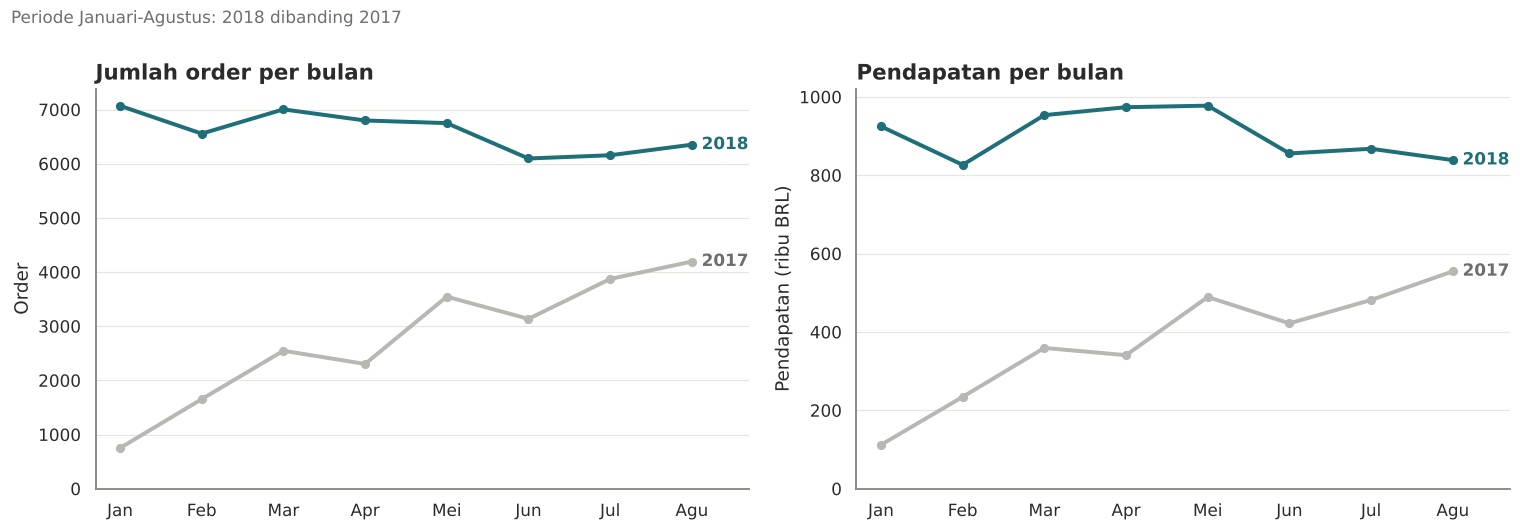

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
metrik = [("jumlah_order", "Jumlah order per bulan", "Order"), ("pendapatan", "Pendapatan per bulan", "Pendapatan (ribu BRL)")]
for ax, (kol, judul, ylab) in zip(axes, metrik):
    for tahun, warna in [(2017, WARNA_2017), (2018, WARNA_AKSEN)]:
        d = tren_df[tren_df.purchase_year == tahun]
        y = d[kol] / (1000 if kol == "pendapatan" else 1)
        ax.plot(d.bulan, y, color=warna, lw=2.6, marker="o", ms=5)
        ax.text(8.12, y.iloc[-1], str(tahun), color=warna if tahun == 2018 else "#6E6E69", va="center", fontweight="bold")
    ax.set_title(judul)
    ax.set_xticks(range(1, 9))
    ax.set_xticklabels(BULAN)
    ax.set_xlim(0.7, 8.7)
    ax.set_ylim(0)
    ax.set_ylabel(ylab)
    ax.yaxis.grid(True, color="#E6E6E1", lw=0.8)
    ax.set_axisbelow(True)
fig.suptitle("Periode Januari-Agustus: 2018 dibanding 2017", x=0.01, ha="left", fontsize=11, color="#6E6E69", y=1.0)
plt.tight_layout()
plt.show()

### Pertanyaan 1 (lanjutan): Kategori produk dengan pendapatan terbesar pada Jan-Agu 2018

Bar chart horizontal dipakai karena nama kategori panjang dan perlu dibandingkan panjang batangnya. Batang diurutkan dari terbesar, hanya tiga teratas yang diberi warna aksen, dan nilai ditulis langsung di ujung batang sehingga sumbu X tidak perlu angka.

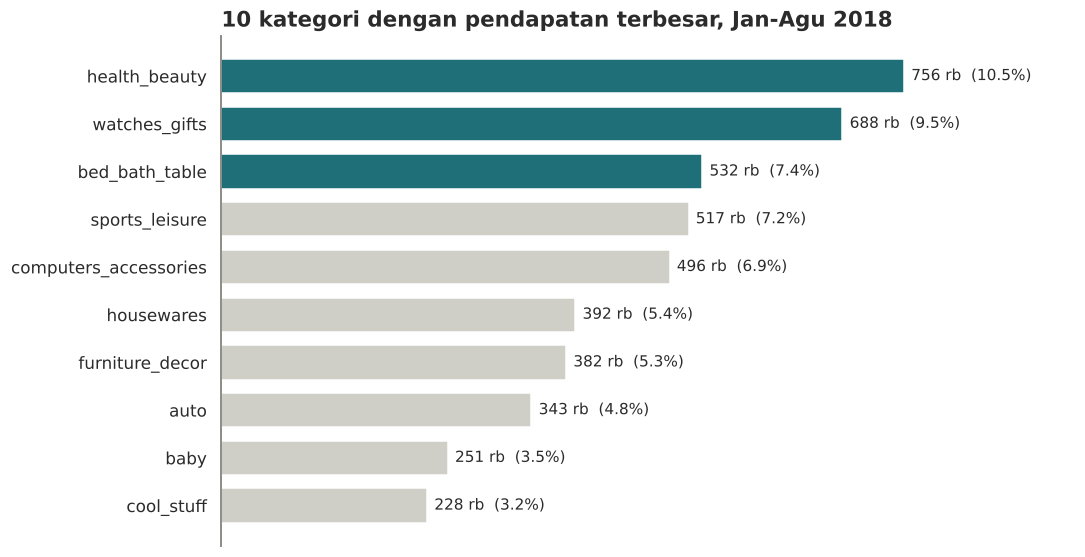

In [39]:
top10 = kategori_2018_df.head(10).iloc[::-1]
warna = [WARNA_AKSEN if i >= len(top10) - 3 else WARNA_BUKAN_SOROT for i in range(len(top10))]

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(top10.index, top10.pendapatan / 1000, color=warna, height=0.72)
for y, (v, p) in enumerate(zip(top10.pendapatan / 1000, top10.persen)):
    ax.text(v + 8, y, f"{v:,.0f} rb  ({p}%)", va="center", fontsize=10)
ax.set_title("10 kategori dengan pendapatan terbesar, Jan-Agu 2018")
ax.set_xlabel("Pendapatan (ribu BRL)")
ax.set_xlim(0, top10.pendapatan.max() / 1000 * 1.25)
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
plt.tight_layout()
plt.show()

**Insight Pertanyaan 1:**
- Pendapatan Jan-Agu 2018 jauh di atas 2017, tetapi jaraknya mengecil dari bulan ke bulan karena 2017 terus naik sedangkan 2018 mendatar dan cenderung turun sejak Juni. Pertumbuhan tahunan yang besar belum berarti momentum masih kuat.
- `health_beauty`, `watches_gifts`, dan `bed_bath_table` adalah tiga kategori dengan pendapatan terbesar (27,4% bersama). `watches_gifts` menarik karena jumlah ordernya lebih sedikit (3.416) daripada `bed_bath_table` (4.844) tetapi pendapatannya lebih besar, jadi harga per orderannya tinggi.

### Pertanyaan 2: Rata-rata review score per state (Jan-Agu 2018)

State dengan kurang dari 100 order dikeluarkan karena rata-ratanya terlalu mudah berubah. Sumbu mulai dari 3,0 supaya perbedaan antarstate terbaca, dan hal itu dinyatakan di judul sumbu agar tidak menyesatkan (batang hanya dipakai untuk membandingkan posisi, bukan besaran absolut). Lima state terendah diberi warna aksen, garis putus-putus menandai rata-rata nasional.

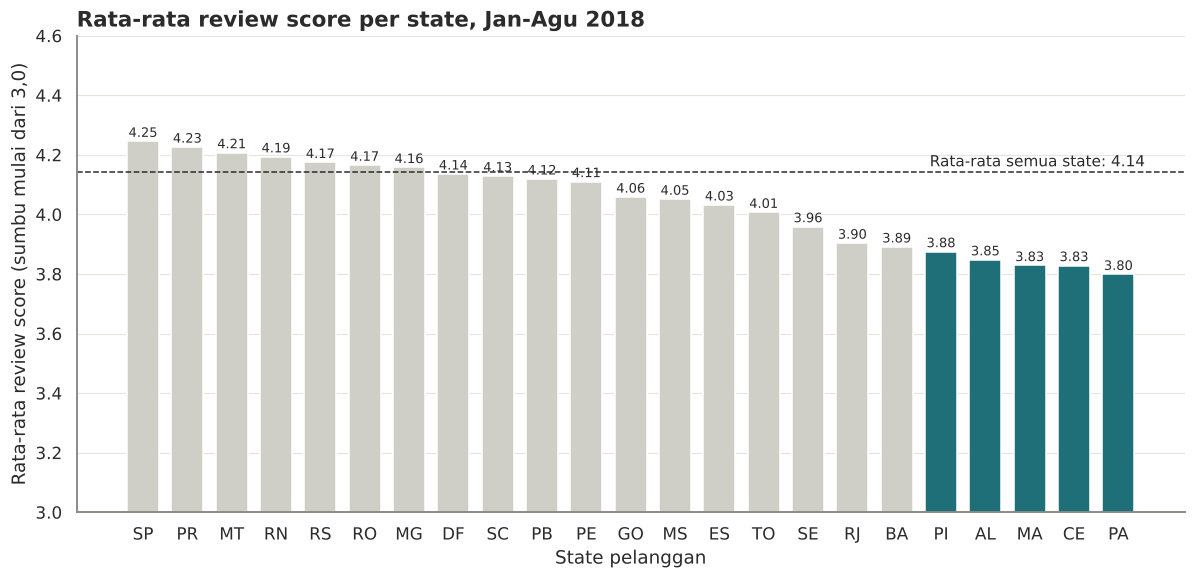

In [40]:
rata_nasional = order_2018_df.review_score.mean()
plot_df = state_df.sort_values("rata2_review", ascending=False)
warna = [WARNA_AKSEN if i >= len(plot_df) - 5 else WARNA_BUKAN_SOROT for i in range(len(plot_df))]

fig, ax = plt.subplots(figsize=(11, 5.4))
ax.bar(plot_df.index, plot_df.rata2_review, color=warna, width=0.72)
ax.axhline(rata_nasional, color=WARNA_TEKS, ls="--", lw=1)
ax.text(len(plot_df) - 0.4, rata_nasional + 0.02, f"Rata-rata semua state: {rata_nasional:.2f}", ha="right", fontsize=10)
for i, v in enumerate(plot_df.rata2_review):
    ax.text(i, v + 0.015, f"{v:.2f}", ha="center", fontsize=8.5)
ax.set_ylim(3.0, 4.6)
ax.set_title("Rata-rata review score per state, Jan-Agu 2018")
ax.set_ylabel("Rata-rata review score (sumbu mulai dari 3,0)")
ax.set_xlabel("State pelanggan")
ax.yaxis.grid(True, color="#E6E6E1", lw=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### Pertanyaan 2 (lanjutan): Review score berdasarkan ketepatan pengiriman

Hasil binning keterlambatan ditampilkan sebagai bar vertikal berurutan dari tepat waktu sampai telat paling lama. Skala 0-5 dipakai penuh karena ini perbandingan besaran, bukan hanya posisi.

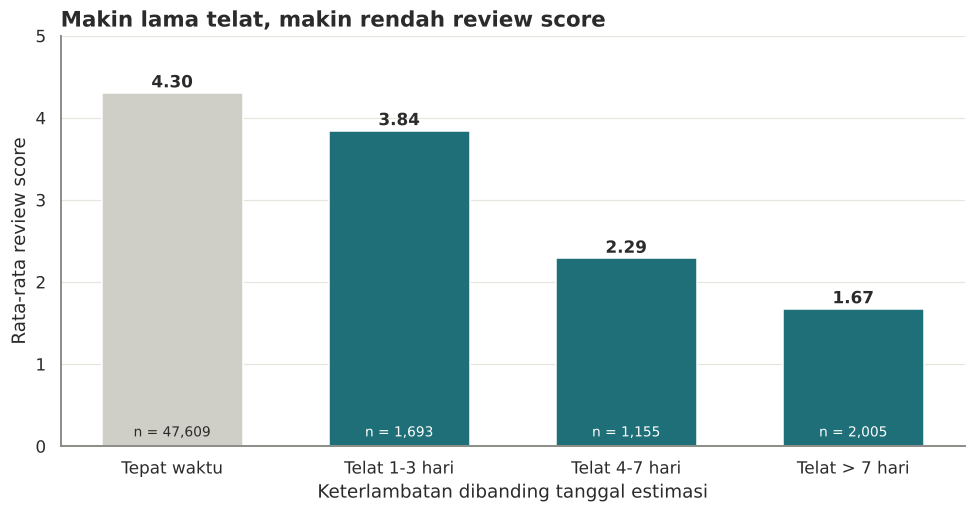

In [41]:
fig, ax = plt.subplots(figsize=(9, 4.8))
warna = [WARNA_BUKAN_SOROT] + [WARNA_AKSEN] * 3
ax.bar(telat_bin_df.index.astype(str), telat_bin_df.rata2_review, color=warna, width=0.62)
for i, (v, n) in enumerate(zip(telat_bin_df.rata2_review, telat_bin_df.jumlah_order)):
    ax.text(i, v + 0.07, f"{v:.2f}", ha="center", fontweight="bold")
    ax.text(i, 0.12, f"n = {n:,}", ha="center", fontsize=9, color="white" if i else WARNA_TEKS)
ax.set_ylim(0, 5)
ax.set_title("Makin lama telat, makin rendah review score")
ax.set_ylabel("Rata-rata review score")
ax.set_xlabel("Keterlambatan dibanding tanggal estimasi")
ax.yaxis.grid(True, color="#E6E6E1", lw=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Insight Pertanyaan 2:**
- State dengan rata-rata review terendah pada Jan-Agu 2018 adalah **Para (PA)** dengan 3,80, diikuti CE, MA, AL, dan PI. Kelimanya berada di wilayah utara dan timur laut Brasil.
- Keterlambatan pengiriman adalah faktor penting: order terlambat lebih dari 7 hari rata-rata hanya mendapat 1,67, sedangkan order tepat waktu 4,30. Namun ia bukan satu-satunya faktor, karena PA dan BA masih paling rendah bahkan jika hanya order tepat waktu yang dihitung.

## Analisis Lanjutan: RFM Analysis, Manual Grouping, dan Geospatial Analysis

### Eksplorasi Pertanyaan 3: Segmentasi pelanggan dengan RFM

**Tujuan teknik:** RFM meringkas perilaku tiap pelanggan dalam tiga angka: *Recency* (berapa hari sejak pembelian terakhir), *Frequency* (jumlah order), dan *Monetary* (total belanja). Dengan itu pelanggan bisa dikelompokkan menurut nilainya bagi bisnis tanpa model machine learning.

Pelanggan diidentifikasi lewat `customer_unique_id` (bukan `customer_id`, yang berganti setiap order). Tanggal acuan recency adalah sehari setelah order terakhir di data. Karena hampir semua pelanggan hanya membeli sekali, Frequency tidak bisa dibagi dengan kuartil (nilainya hampir semua 1), sehingga dikelompokkan manual.

In [42]:
tanggal_acuan = all_df.order_purchase_timestamp.max().normalize() + pd.Timedelta(days=1)

rfm_df = all_df.groupby("customer_unique_id").agg(
    last_purchase=("order_purchase_timestamp", "max"),
    frequency=("order_id", "nunique"),
    monetary=("price", "sum"),
).reset_index()
rfm_df["recency"] = (tanggal_acuan - rfm_df.last_purchase).dt.days

print("Tanggal acuan:", tanggal_acuan.date())
print("Jumlah pelanggan:", len(rfm_df))
print(rfm_df[["recency", "frequency", "monetary"]].describe().round(1))
print("\nDistribusi frequency:")
print(rfm_df.frequency.value_counts().sort_index())

Tanggal acuan: 2018-08-30
Jumlah pelanggan: 93350
       recency  frequency  monetary
count  93350.0    93350.0   93350.0
mean     237.5        1.0     141.6
std      152.6        0.2     215.7
min        0.0        1.0       0.8
25%      114.0        1.0      47.6
50%      219.0        1.0      89.7
75%      346.0        1.0     154.7
max      713.0       15.0   13440.0

Distribusi frequency:
frequency
1     90549
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64


In [43]:
# Manual grouping / binning
# Recency: 1 = paling lama tidak membeli, 4 = paling baru (kuartil)
rfm_df["r_score"] = pd.qcut(rfm_df.recency, 4, labels=[4, 3, 2, 1]).astype(int)
# Monetary: 1 = belanja terendah, 4 = tertinggi (kuartil)
rfm_df["m_score"] = pd.qcut(rfm_df.monetary, 4, labels=[1, 2, 3, 4]).astype(int)
# Frequency: dikelompokkan manual karena distribusinya sangat miring
rfm_df["f_group"] = pd.cut(rfm_df.frequency, bins=[0, 1, np.inf], labels=["Sekali beli", "Berulang (2+ order)"])


def beri_segmen(r):
    if r.frequency >= 2:
        return "Pelanggan berulang"
    if r.m_score == 4 and r.r_score >= 3:
        return "Bernilai tinggi, masih aktif"
    if r.m_score == 4:
        return "Bernilai tinggi, mulai pasif"
    if r.r_score >= 3:
        return "Baru, belanja kecil-menengah"
    return "Pasif, belanja kecil-menengah"


rfm_df["segmen"] = rfm_df.apply(beri_segmen, axis=1)

segmen_df = rfm_df.groupby("segmen").agg(
    jumlah_pelanggan=("customer_unique_id", "count"),
    total_pendapatan=("monetary", "sum"),
    rata2_belanja=("monetary", "mean"),
    rata2_recency=("recency", "mean"),
)
segmen_df["persen_pelanggan"] = segmen_df.jumlah_pelanggan / segmen_df.jumlah_pelanggan.sum() * 100
segmen_df["persen_pendapatan"] = segmen_df.total_pendapatan / segmen_df.total_pendapatan.sum() * 100
segmen_df = segmen_df.sort_values("total_pendapatan", ascending=False)
segmen_df.round(1)

,jumlah_pelanggan,total_pendapatan,rata2_belanja,rata2_recency,persen_pelanggan,persen_pendapatan
segmen,,,,,,
"Bernilai tinggi, mulai pasif",10879,3839248.3,352.9,366.4,11.7,29.0
"Bernilai tinggi, masih aktif",10780,3807916.6,353.2,111.9,11.5,28.8
"Baru, belanja kecil-menengah",34642,2463641.4,71.1,112.0,37.1,18.6
"Pasif, belanja kecil-menengah",34248,2381033.9,69.5,364.4,36.7,18.0
Pelanggan berulang,2801,728408.8,260.1,219.8,3.0,5.5


### Eksplorasi Geospatial: sebaran pelanggan bernilai tinggi

**Tujuan teknik:** analisis geospasial memakai koordinat pelanggan (rata-rata per kode pos) untuk melihat apakah pelanggan bernilai tinggi menumpuk di wilayah tertentu, sehingga kampanye atau logistik bisa difokuskan di sana. Lokasi pelanggan diambil dari order terakhirnya.

In [44]:
lokasi_df = (
    all_df.sort_values("order_purchase_timestamp")
    .drop_duplicates("customer_unique_id", keep="last")[["customer_unique_id", "customer_state", "customer_lat", "customer_lng"]]
)
rfm_geo_df = rfm_df.merge(lokasi_df, on="customer_unique_id", how="left")
rfm_geo_df["bernilai_tinggi"] = rfm_geo_df.segmen.isin(["Bernilai tinggi, masih aktif", "Bernilai tinggi, mulai pasif"])

state_rfm_df = rfm_geo_df.groupby("customer_state").agg(
    jumlah_pelanggan=("customer_unique_id", "count"),
    pelanggan_tinggi=("bernilai_tinggi", "sum"),
    pendapatan=("monetary", "sum"),
)
state_rfm_df["persen_tinggi_dalam_state"] = state_rfm_df.pelanggan_tinggi / state_rfm_df.jumlah_pelanggan * 100
state_rfm_df["persen_pendapatan_nasional"] = state_rfm_df.pendapatan / state_rfm_df.pendapatan.sum() * 100
state_rfm_df = state_rfm_df.sort_values("pendapatan", ascending=False)
state_rfm_df.round(1).head(10)

,jumlah_pelanggan,pelanggan_tinggi,pendapatan,persen_tinggi_dalam_state,persen_pendapatan_nasional
customer_state,,,,,
SP,39143,8089,5068477.5,20.7,38.3
RJ,11914,2881,1759511.9,24.2,13.3
MG,10995,2535,1552242.8,23.1,11.7
RS,5166,1211,728798.5,23.4,5.5
PR,4766,1057,665108.6,22.2,5.0
SC,3446,855,506710.1,24.8,3.8
BA,3156,818,493354.2,25.9,3.7
DF,2016,501,295697.7,24.9,2.2
GO,1893,480,283123.7,25.4,2.1


In [45]:
tinggi_df = rfm_geo_df[rfm_geo_df.bernilai_tinggi]
print("Pelanggan bernilai tinggi:", len(tinggi_df), "| pendapatan:", round(tinggi_df.monetary.sum() / rfm_df.monetary.sum() * 100, 1), "% dari total")
print("Pelanggan bernilai tinggi tanpa koordinat:", tinggi_df.customer_lat.isna().sum())
print("\nKonsentrasi 3 state teratas pada pelanggan bernilai tinggi:")
print((tinggi_df.customer_state.value_counts(normalize=True).head(3) * 100).round(1))

Pelanggan bernilai tinggi: 21659 | pendapatan: 57.8 % dari total
Pelanggan bernilai tinggi tanpa koordinat: 65

Konsentrasi 3 state teratas pada pelanggan bernilai tinggi:
customer_state
SP    37.3
RJ    13.3
MG    11.7
Name: proportion, dtype: float64


**Insight Eksplorasi Pertanyaan 3:**
- Dari 93.350 pelanggan unik, 97% (90.549) hanya membeli sekali. Hanya 3% pelanggan berulang, dan mereka menyumbang 5,5% pendapatan.
- Pelanggan bernilai tinggi (kuartil belanja teratas, rata-rata sekitar 353 BRL) hanya 23,2% dari pelanggan tetapi menyumbang **57,8%** pendapatan. Setengah dari mereka masih aktif (recency rata-rata 112 hari) dan setengah lagi sudah pasif (rata-rata 366 hari tidak membeli).
- Pelanggan belanja kecil-menengah (sekitar 70 BRL) adalah 73,8% pelanggan tetapi hanya 36,6% pendapatan.
- Sebaran geografis mengikuti jumlah penduduk: SP, RJ, dan MG menyumbang 62,3% pelanggan bernilai tinggi. Persentase pelanggan bernilai tinggi di dalam tiap state justru mirip (20-26%), pada 10 state terbesar, dengan SP terendah (20,7%) tetapi paling banyak secara jumlah.

### Pertanyaan 3: Kontribusi pendapatan tiap segmen RFM

Bar horizontal dengan dua batang per segmen menunjukkan persentase pelanggan dan persentase pendapatan, sehingga terlihat jelas segmen yang kontribusinya lebih besar dari jumlah orangnya.

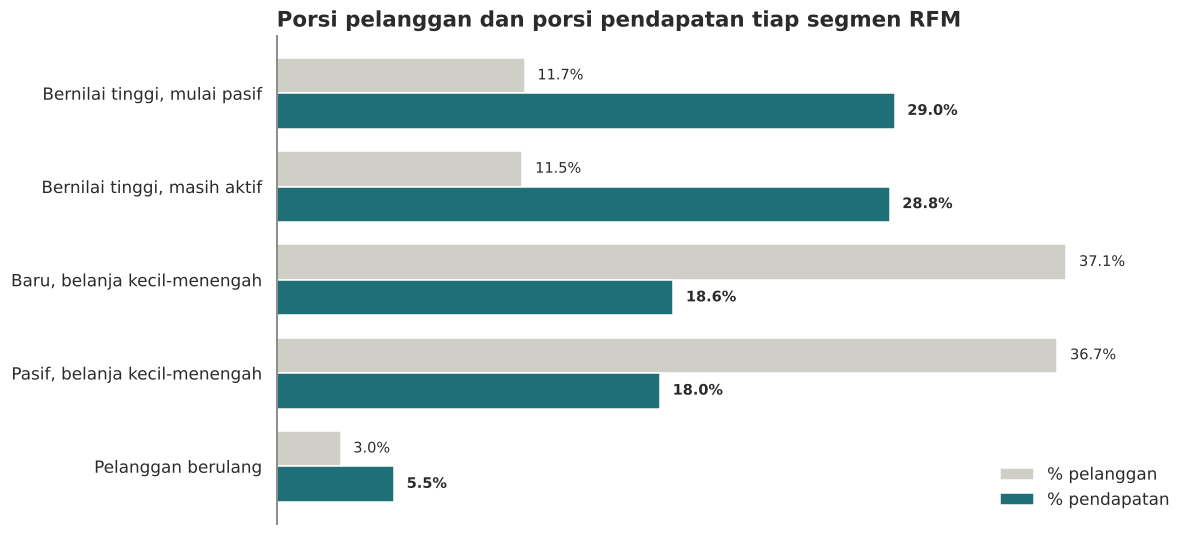

In [46]:
plot_df = segmen_df.sort_values("total_pendapatan")
y = np.arange(len(plot_df))
h = 0.38
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(y + h / 2, plot_df.persen_pelanggan, height=h, color=WARNA_BUKAN_SOROT, label="% pelanggan")
ax.barh(y - h / 2, plot_df.persen_pendapatan, height=h, color=WARNA_AKSEN, label="% pendapatan")
for i, (a, b) in enumerate(zip(plot_df.persen_pelanggan, plot_df.persen_pendapatan)):
    ax.text(a + 0.6, i + h / 2, f"{a:.1f}%", va="center", fontsize=9.5)
    ax.text(b + 0.6, i - h / 2, f"{b:.1f}%", va="center", fontsize=9.5, fontweight="bold")
ax.set_yticks(y)
ax.set_yticklabels(plot_df.index)
ax.set_title("Porsi pelanggan dan porsi pendapatan tiap segmen RFM")
ax.legend(frameon=False, loc="lower right")
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.set_xlim(0, max(plot_df.persen_pelanggan.max(), plot_df.persen_pendapatan.max()) * 1.15)
plt.tight_layout()
plt.show()

### Pertanyaan 3 (lanjutan): Peta sebaran pelanggan bernilai tinggi

Setiap titik adalah satu pelanggan bernilai tinggi pada koordinat kode posnya. Titik dibuat transparan agar area padat terlihat lebih gelap tanpa menutupi titik lain, dan pelanggan lain digambar abu-abu tipis sebagai latar. Sisi sebelahnya menampilkan lima state dengan pelanggan bernilai tinggi terbanyak.

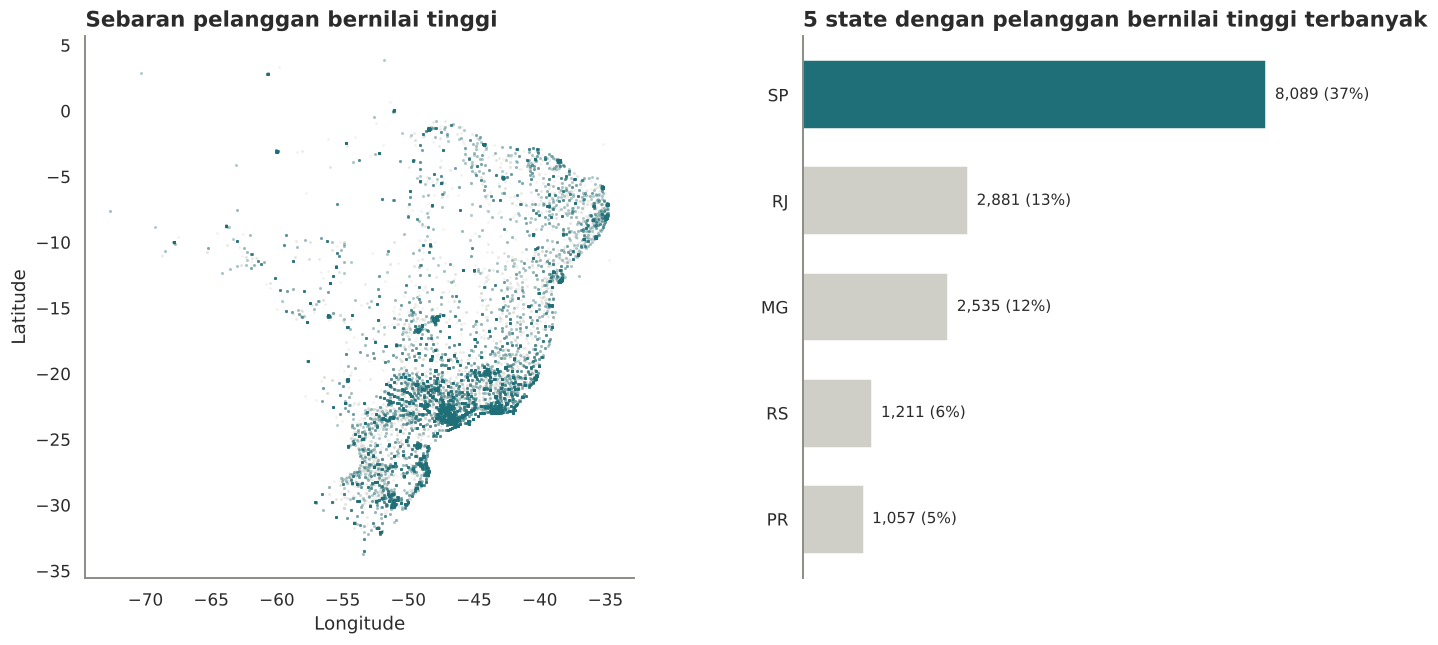

In [47]:
latar_df = rfm_geo_df[~rfm_geo_df.bernilai_tinggi].dropna(subset=["customer_lat"])
tinggi_geo_df = tinggi_df.dropna(subset=["customer_lat"])
top5 = tinggi_df.customer_state.value_counts().head(5).iloc[::-1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.5, 1]})
ax1.scatter(latar_df.customer_lng, latar_df.customer_lat, s=3, color="#D9D9D3", alpha=0.35, linewidths=0)
ax1.scatter(tinggi_geo_df.customer_lng, tinggi_geo_df.customer_lat, s=4, color=WARNA_AKSEN, alpha=0.35, linewidths=0)
ax1.set_aspect("equal")
ax1.set_title("Sebaran pelanggan bernilai tinggi")
ax1.set_xlabel("Longitude")
ax1.set_ylabel("Latitude")

ax2.barh(top5.index, top5.values, color=[WARNA_AKSEN if i == len(top5) - 1 else WARNA_BUKAN_SOROT for i in range(len(top5))], height=0.65)
for i, v in enumerate(top5.values):
    ax2.text(v + 150, i, f"{v:,} ({v / len(tinggi_df) * 100:.0f}%)", va="center", fontsize=10)
ax2.set_title("5 state dengan pelanggan bernilai tinggi terbanyak")
ax2.xaxis.set_visible(False)
ax2.spines["bottom"].set_visible(False)
ax2.set_xlim(0, top5.max() * 1.3)
plt.tight_layout()
plt.show()

**Insight Pertanyaan 3:**
- Segmen yang paling bernilai adalah dua kelompok pelanggan bernilai tinggi (masih aktif dan mulai pasif). Masing-masing hanya sekitar 11,5% pelanggan tetapi menyumbang sekitar 29% pendapatan, hampir 2,5 kali porsi jumlah orangnya. Gabungannya 57,8% dari total.
- Pelanggan bernilai tinggi menumpuk di koridor tenggara-selatan Brasil: **Sao Paulo (37%)**, Rio de Janeiro (13%), dan Minas Gerais (12%), yang bersama-sama 62% dari seluruh pelanggan bernilai tinggi. Peta menunjukkan kepadatan terbesar di sekitar kota Sao Paulo dan Rio, lalu menyebar sepanjang pesisir.

## Menyimpan Data untuk Dashboard

Dashboard Streamlit memakai data yang sudah bersih dan hanya kolom yang dibutuhkan, agar berkas ringan dan dashboard cepat dimuat. Perhitungan RFM dilakukan ulang di dashboard dari data ini.

In [48]:
import os
os.makedirs("dashboard", exist_ok=True)
kolom_dashboard = ["order_id", "order_purchase_timestamp", "customer_unique_id", "customer_state", "customer_lat",
                   "customer_lng", "product_category_name_english", "price", "review_score", "delay_days"]
main_df = all_df[kolom_dashboard].copy()
main_df["customer_lat"] = main_df.customer_lat.round(3)
main_df["customer_lng"] = main_df.customer_lng.round(3)
main_df["delay_days"] = main_df.delay_days.round(2)
main_df.to_csv("dashboard/main_data.csv", index=False)
print(main_df.shape, "|", round(os.path.getsize("dashboard/main_data.csv") / 1e6, 1), "MB")

(110189, 10) | 14.8 MB


## Conclusion

**Kesimpulan Pertanyaan 1 (tren order, pendapatan, dan kategori):**
Jumlah order dan pendapatan Jan-Agu 2018 naik sekitar 140% dibanding Jan-Agu 2017 (52.777 vs 21.997 order; 7,22 juta vs 2,99 juta BRL), dengan nilai per order yang hampir sama (sekitar 136 BRL). Meski begitu, sepanjang 2018 pertumbuhan mendatar dan pendapatan turun dari puncak 977 ribu BRL (Mei) menjadi 839 ribu BRL (Agustus). Kategori penyumbang terbesar adalah `health_beauty` (10,5%), `watches_gifts` (9,5%), dan `bed_bath_table` (7,4%).

**Kesimpulan Pertanyaan 2 (review score per state dan keterlambatan):**
State dengan rata-rata review terendah pada Jan-Agu 2018 adalah Para (3,80), diikuti Ceara, Maranhao, Alagoas, dan Piaui, semuanya di bawah rata-rata nasional 4,14. Keterlambatan adalah faktor yang besar: order terlambat rata-rata mendapat 2,57 dibanding 4,30 untuk yang tepat waktu, dan makin lama telatnya makin rendah skornya (1,67 untuk telat lebih dari 7 hari). Namun keterlambatan bukan satu-satunya penyebab, karena sebagian selisih antarstate tetap ada pada order yang tepat waktu.

**Kesimpulan Pertanyaan 3 (segmen RFM dan wilayah):**
Pelanggan bernilai tinggi (23,2% pelanggan) menyumbang 57,8% pendapatan, sedangkan 97% pelanggan hanya membeli sekali. Pelanggan bernilai tinggi terkonsentrasi di Sao Paulo (37%), Rio de Janeiro (13%), dan Minas Gerais (12%). Separuh pelanggan bernilai tinggi sudah pasif, rata-rata sekitar satu tahun tidak membeli lagi.

**Rekomendasi (action item):**
1. **Aktifkan kembali pelanggan bernilai tinggi yang mulai pasif** (10.879 pelanggan, 29% pendapatan, rata-rata belanja 353 BRL). Kirim voucher atau penawaran personal khusus segmen ini, dimulai dari SP, RJ, dan MG yang menampung 62% dari mereka, lalu ukur berapa persen yang membeli lagi dalam 30 hari.
2. **Kurangi keterlambatan di state dengan review terendah** (PA, CE, MA, AL, PI) dengan memperkirakan tanggal estimasi lebih realistis di wilayah tersebut dan bekerja sama dengan penjual atau kurir yang lebih dekat. Targetnya menurunkan persentase order terlambat dari 17-24% mendekati rata-rata nasional 9,3%. Order yang berisiko telat lebih dari 3 hari perlu diberi notifikasi proaktif karena dari titik itu review turun tajam ke 2,29 atau lebih rendah.
3. **Dorong pertumbuhan baru karena momentum 2018 mendatar.** Prioritaskan stok dan promosi pada `health_beauty`, `watches_gifts`, dan `bed_bath_table`, dan ubah pelanggan sekali beli menjadi pembeli ulang lewat program penawaran setelah pembelian pertama, karena hanya 3% pelanggan yang membeli lebih dari sekali.

**Keterbatasan:** data tidak punya informasi biaya, sehingga "bernilai" dihitung dari pendapatan, bukan laba. Analisis review hanya mencakup order yang diberi review (sekitar 99%), dan sebagian kecil pelanggan (sekitar 0,3%) tidak punya koordinat sehingga tidak muncul di peta.